# 05 — Engineered features and robustness

Two questions, both answered with the same grouped 5-fold cross-validation on the training set (the test set is not used):
1. **Engineered features:** do simple writing-style measures (sentence length, vocabulary richness, semicolon use) help, on their own or added to the TF-IDF word features?
2. **Robustness:** a model trained on the middle 5,000 words of each book — does it still work on a *different* part of the same books? This is the "robustness analysis" alternative suggested in Week 10 for non-image projects.

## Setup

In [1]:
import sys
import json
import time
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import f1_score

from src import config
from src.text import clean_text, chunk, style_features, STYLE_FEATURES

In [2]:
train = pd.read_csv(config.PROCESSED_DIR / "train.csv")
PERIODS = ["pre-1750", "1750-1799", "1800-1849", "1850-1899", "1900-1918"]
y = train["period"]
groups = train["group"]

cv = StratifiedGroupKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)
folds = list(cv.split(train, y, groups))
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}

def evaluate(name, model, X):
    s = cross_validate(model, X, y, groups=groups, cv=cv, scoring=scoring)
    return {"model": name,
            "macro_f1": s["test_macro_f1"].mean(), "macro_f1_std": s["test_macro_f1"].std(),
            "accuracy": s["test_accuracy"].mean(), "fit_time_s": s["fit_time"].mean(),
            "fold_macro_f1": s["test_macro_f1"].round(3).tolist()}

def tfidf():
    return TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{2,}\b", min_df=10)

def logreg():
    return LogisticRegression(C=100, max_iter=2000)

def boosting():
    return GradientBoostingClassifier(n_estimators=400, learning_rate=0.1, max_depth=3,
                                      max_features="sqrt", random_state=config.RANDOM_STATE)

reference = pd.read_csv(config.ROOT / "reports" / "experiment_results.csv").set_index("model")
reference = reference.loc[["Zero-R", "LogReg C=100", "Boosting rounds=400"]]
print("Train:", train.shape)
reference[["macro_f1", "macro_f1_std", "accuracy"]].round(3)

Train: (288, 6)


,macro_f1,macro_f1_std,accuracy
model,,,
Zero-R,0.084,0.002,0.264
LogReg C=100,0.460,0.067,0.459
Boosting rounds=400,0.506,0.064,0.497


## Part 1: Engineered features

The TF-IDF features only see *which words* are used (letters only). Three simple style measures add information about *how* the text is written:

| Feature | How it is calculated | Why it might show the period |
|---|---|---|
| `avg_sentence_words` | words ÷ sentences (split at `.`, `!`, `?`) | Older prose tends to use longer sentences |
| `type_token_ratio` | distinct words ÷ total words | Vocabulary richness; comparable between books because every excerpt is exactly 5,000 words |
| `semicolons_per_1000` | semicolons per 1,000 words | Heavy semicolon use is typical of 18th- and 19th-century prose; punctuation is invisible to the TF-IDF features |

Each feature is calculated from one excerpt on its own, with nothing learned from other books, so computing them before cross-validation cannot leak information between folds. The functions are in `src/text.py`.

Limitation: the sentence split is crude: abbreviations such as "Mr." and "Dr." count as sentence ends, and verse or plays with little punctuation give very long "sentences".

In [3]:
feats = pd.DataFrame([style_features(t) for t in train["excerpt"]])
train[STYLE_FEATURES] = feats.values
train.groupby("period")[STYLE_FEATURES].median().reindex(PERIODS).round(3)

,avg_sentence_words,type_token_ratio,semicolons_per_1000
period,,,
pre-1750,28.219,0.264,11.8
1750-1799,27.027,0.278,11.4
1800-1849,24.097,0.296,9.9
1850-1899,19.084,0.270,7.6
1900-1918,16.921,0.273,4.5


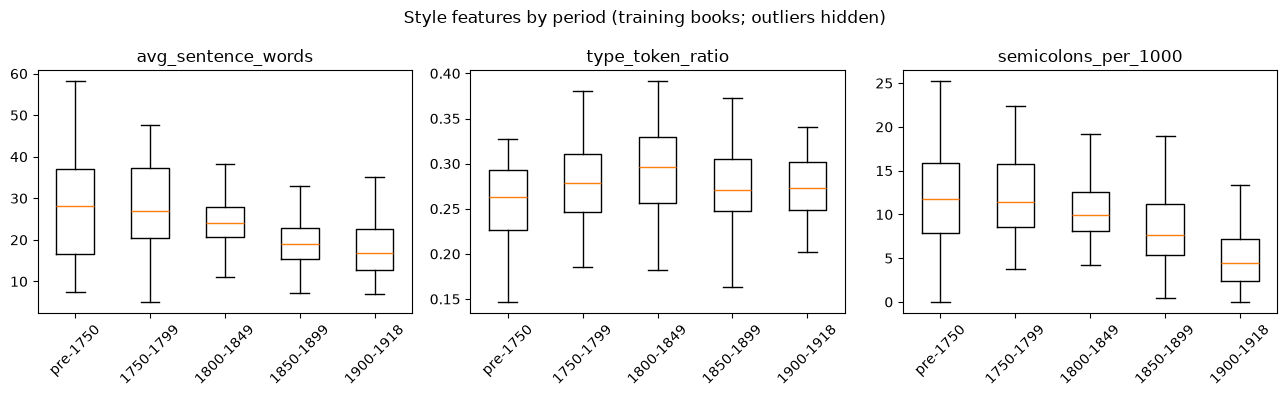

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, f in zip(axes, STYLE_FEATURES):
    ax.boxplot([train.loc[train["period"] == p, f] for p in PERIODS], showfliers=False)
    ax.set_xticks(range(1, 6), PERIODS, rotation=45)
    ax.set_title(f)
plt.suptitle("Style features by period (training books; outliers hidden)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "style_features_by_period.png", dpi=150)
plt.show()

**Findings:** two of the three features change steadily over time. The median sentence length falls in every period, from 28.2 words (pre-1750) to 16.9 (1900–1918), and semicolon use falls from 11.8 to 4.5 per 1,000 words. Vocabulary richness (type-token ratio) shows no clear trend (0.26–0.30, highest in 1800–1849). The boxes overlap a lot, so no single feature separates the periods on its own.

### Do the features help?

Three tests, on the same 5 folds as notebook 03:
- **Style features alone** (3 numbers per book), with logistic regression (after scaling) and boosting: how much do they know on their own?
- **TF-IDF + style features** with logistic regression (C=100) and boosting (400 rounds), the two reference models from notebook 03, with no other changes.

Note: boosting looks at a random √(number of features) subset at each split (`max_features="sqrt"`). With several thousand word features, each style feature is only offered at about 1 in 70 splits, so boosting may barely use them.

In [5]:
results = []
start = time.time()

results.append(evaluate("Style only + LogReg", make_pipeline(StandardScaler(), logreg()), train[STYLE_FEATURES]))
results.append(evaluate("Style only + Boosting", boosting(), train[STYLE_FEATURES]))

def words_and_style():
    return make_column_transformer((tfidf(), "excerpt"), (StandardScaler(), STYLE_FEATURES))

X_both = train[["excerpt"] + STYLE_FEATURES]
results.append(evaluate("TF-IDF + style + LogReg", make_pipeline(words_and_style(), logreg()), X_both))
results.append(evaluate("TF-IDF + style + Boosting", make_pipeline(words_and_style(), boosting()), X_both))
print(f"Took {time.time() - start:.0f} s")

feature_table = pd.DataFrame(results)
feature_table[["model", "macro_f1", "macro_f1_std", "accuracy", "fit_time_s"]].round(3)

Took 86 s


,model,macro_f1,macro_f1_std,accuracy,fit_time_s
0,Style only + LogReg,0.311,0.041,0.358,0.030
1,Style only + Boosting,0.370,0.041,0.400,3.454
2,TF-IDF + style + LogReg,0.463,0.070,0.466,3.072
3,TF-IDF + style + Boosting,0.482,0.063,0.490,9.818


In [6]:
paired = pd.DataFrame({"fold": range(1, 6)})
for base, new in [("LogReg C=100", "TF-IDF + style + LogReg"), ("Boosting rounds=400", "TF-IDF + style + Boosting")]:
    before = json.loads(reference.loc[base, "fold_macro_f1"])
    after = feature_table.set_index("model").loc[new, "fold_macro_f1"]
    paired[f"{base}: TF-IDF only"] = before
    paired[f"{base}: + style"] = after
    diff = np.subtract(after, before)
    print(f"{base}: adding style features changes macro-F1 by {diff.mean():+.3f} on average, better on {(diff > 0).sum()} of 5 folds")
paired

LogReg C=100: adding style features changes macro-F1 by +0.003 on average, better on 3 of 5 folds
Boosting rounds=400: adding style features changes macro-F1 by -0.023 on average, better on 1 of 5 folds


,fold,LogReg C=100: TF-IDF only,LogReg C=100: + style,Boosting rounds=400: TF-IDF only,Boosting rounds=400: + style
0,1,0.412,0.442,0.482,0.458
1,2,0.378,0.392,0.433,0.419
2,3,0.440,0.389,0.493,0.421
3,4,0.567,0.538,0.495,0.536
4,5,0.502,0.553,0.625,0.577


**Findings:**
- On their own, the three style features carry real information: 0.370 macro-F1 with boosting and 0.311 with logistic regression, from just 3 numbers per book (Zero-R: 0.084; TF-IDF with boosting: 0.506).
- Added to the TF-IDF features, they do not help. Logistic regression goes from 0.460 to 0.463 (better on only 3 of 5 folds), which is no real change. Boosting goes from 0.506 to 0.482 (worse on 4 of 5 folds), probably because with `max_features="sqrt"` it rarely gets to use them, and adding columns changes which random word subsets it sees.
- What the style features capture (shorter sentences, fewer semicolons over time) may already be reflected in the word features, e.g. through common function words.

**Decision:** the style features are not added to the final model. They are kept as an interpretable description of how the writing changes over time.

## Part 2: Robustness to the excerpt position

Every model so far was trained and evaluated on the **middle** 5,000 words of each book. A model that has really learned the language of a period should also work on other parts of the same books; one that has learned something specific to the middle of books (or to particular passages) will not.

Test: in each fold, the model is trained on the middle excerpts of the training books as usual, then evaluated on the validation books three times, using 5,000-word excerpts taken **25%**, **50%** (the usual middle) and **75%** of the way through each book. The very start and end are avoided because they contain title pages, prefaces, modern introductions and end notes (see notebook 02).

The texts are re-read and cleaned exactly as in notebook 02. As a check, the 50% excerpts must be identical to the saved ones.

In [7]:
BOOKS_DIR = config.RAW_DIR / "books"
texts = [clean_text((BOOKS_DIR / f"{i}.txt").read_text(encoding="utf-8", errors="replace")) for i in train["id"]]

POSITIONS = [0.25, 0.5, 0.75]
excerpts = {p: pd.Series([chunk(t, position=p) for t in texts]) for p in POSITIONS}

print("50% excerpts identical to saved ones:", (excerpts[0.5] == train["excerpt"]).all())
# For shorter books the 25% / 75% excerpts partly overlap the middle one (same words), which makes the test easier
def overlap_with_middle(t, p, n=5000):
    spare = max(len(t.split()) - n, 0)
    return max(0, n - abs(int(spare * 0.5) - int(spare * p))) / n

for p in [0.25, 0.75]:
    ov = pd.Series([overlap_with_middle(t, p) for t in texts])
    print(f"{p:.0%} excerpt: shares words with the middle one in {(ov > 0).mean():.0%} of books; "
          f"average overlap {ov.mean():.0%} of its words")

50% excerpts identical to saved ones: True
25% excerpt: shares words with the middle one in 23% of books; average overlap 13% of its words
75% excerpt: shares words with the middle one in 23% of books; average overlap 13% of its words


In [8]:
models = {"LogReg C=100": lambda: make_pipeline(tfidf(), logreg()),
          "Boosting rounds=400": lambda: make_pipeline(tfidf(), boosting())}

rows = []
start = time.time()
for name, make in models.items():
    for k, (tr, va) in enumerate(folds, start=1):
        t0 = time.time()
        model = make().fit(train["excerpt"].iloc[tr], y.iloc[tr])
        fit_s = time.time() - t0
        for p in POSITIONS:
            pred = model.predict(excerpts[p].iloc[va])
            rows.append({"model": name, "fold": k, "position": f"{p:.0%}",
                         "macro_f1": f1_score(y.iloc[va], pred, average="macro"), "fit_time_s": fit_s})
print(f"Took {time.time() - start:.0f} s")

robust = pd.DataFrame(rows)
def std0(s):
    return np.std(s)  # divide by n, as in notebooks 03-04

robust_table = robust.groupby(["model", "position"])["macro_f1"].agg(["mean", std0]).unstack("position")
print("Fit time per fold, this session:", robust.groupby("model")["fit_time_s"].mean().round(1).to_dict())
robust_table.round(3)

Took 76 s
Fit time per fold, this session: {'Boosting rounds=400': 10.5, 'LogReg C=100': 3.0}


mean                 std0              
position               25%    50%    75%    25%    50%    75%
model                                                        
Boosting rounds=400  0.481  0.506  0.514  0.079  0.064  0.049
LogReg C=100         0.445  0.460  0.462  0.054  0.067  0.089

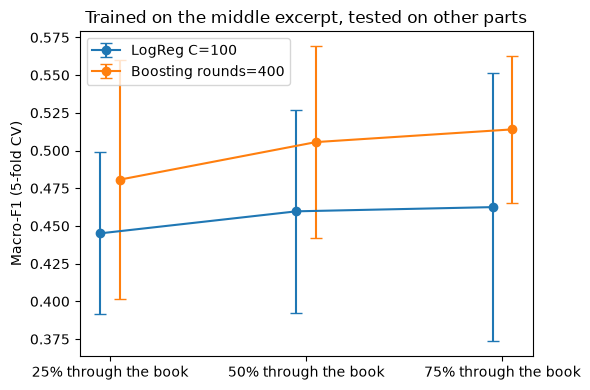

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, offset in zip(models, [-0.05, 0.05]):
    m = robust[robust["model"] == name].groupby("position")["macro_f1"]
    xs = np.arange(len(POSITIONS)) + offset
    ax.errorbar(xs, m.mean(), yerr=m.agg(std0), marker="o", capsize=4, label=name)
ax.set_xticks(range(len(POSITIONS)), [f"{p:.0%} through the book" for p in POSITIONS])
ax.set_ylabel("Macro-F1 (5-fold CV)")
ax.set_title("Trained on the middle excerpt, tested on other parts")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "robustness_excerpt_position.png", dpi=150)
plt.show()

**Findings:**
- Both models keep almost all of their performance on other parts of the books. Boosting scores 0.481 / 0.506 / 0.514 on excerpts 25% / 50% / 75% through the book; logistic regression 0.445 / 0.460 / 0.462. The largest drop (0.025) is much smaller than the fold spread (±0.05–0.09).
- The overlap check shows this is mostly genuinely different text: only 23% of books have any overlap between the 25% (or 75%) excerpt and the middle one, sharing 13% of words on average.
- So the models have learned something general about each period's language, not something specific to the middle of books. The 50% scores match notebook 03 exactly (0.506 and 0.460), which confirms the same books, cleaning and folds.

In [10]:
robust_rows = robust.groupby(["model", "position"]).agg(
    macro_f1=("macro_f1", "mean"), macro_f1_std=("macro_f1", std0), fit_time_s=("fit_time_s", "mean")).reset_index()
robust_rows["model"] = robust_rows["model"] + ", excerpt at " + robust_rows["position"]
out = pd.concat([feature_table, robust_rows.drop(columns="position")], ignore_index=True)
out.to_csv(config.ROOT / "reports" / "features_robustness_results.csv", index=False)
print("Saved", len(out), "rows")

Saved 10 rows


## Conclusion

- **Engineered features:** sentence length and semicolon use fall steadily from the 1700s to the 1900s and predict the period well above chance on their own, but adding them to the word features does not improve either model. The extra complexity is **not justified** for the final model, though they are a useful, easy-to-explain description of how the language changed.
- **Robustness (Week 10 alternative):** the preferred model (boosting) is stable when tested on different parts of the same books (changes ≤ 0.025 macro-F1), so the excerpt position chosen in notebook 02 is not driving the results. This check added no complexity to the model itself, only to the evaluation, and it **strengthens confidence** in the cross-validation estimate.
- Neither experiment changes the preferred model: gradient boosting on TF-IDF word features, as in notebook 03. All results are cross-validation only (experiments E21–E23 in `reports/experiment_log.md`).